# 4 · What did the predictions get right—and miss?

The selected model is L1 logistic regression with team and player histories, C=.1. It was fitted through 2022–23 and frozen before the original 2023–24 evaluation. This notebook follows the predictions through winner selection, probability quality, calibration, explanation and mistakes.

The better-record rule is a **new retrospective reporting comparison**, added after those test results were already known. It uses a fixed definition: higher pregame winning percentage, exact ties to home. I do not refit the model, change its inputs, recalibrate it or search for a better favorite threshold. The distinction protects the meaning of the original test while making the practical basketball comparison clearer.

In [1]:
from pathlib import Path
import sys, json

ROOT = Path.cwd() if (Path.cwd() / "Data").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.charts import feature_label

TABLES = ROOT / "artifacts/tables"
FIGURES = ROOT / "artifacts/figures"
CLAY, TEAL = "#b55832", "#427b83"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.figsize": (9, 4),
        "axes.grid": False,
        "font.size": 10,
    }
)
pd.set_option("display.max_columns", 14)


def finish(fig, filename=None):
    fig.tight_layout()
    if filename:
        fig.savefig(FIGURES / filename, dpi=160, bbox_inches="tight")
    plt.show()

In [2]:
from sklearn.metrics import confusion_matrix, roc_curve
from src.analysis import paired_accuracy_bootstrap, linear_contributions
import joblib

results = json.loads((TABLES / "results.json").read_text())
story = json.loads((TABLES / "story.json").read_text())
selection = json.loads((ROOT / "artifacts/models/selection.json").read_text())
test = pd.read_csv(TABLES / "record_comparison_games.csv", parse_dates=["gamedate"])
original = pd.read_csv(TABLES / "test_predictions.csv")
assert test.nbagameid.tolist() == original.nbagameid.tolist()
np.testing.assert_array_equal(test.probability, original.probability)
print("Identical frozen probabilities on", len(test), "games.")
display(pd.read_csv(TABLES / "coverage.csv").query("season==2023"))

Identical frozen probabilities on 1074 games.


,season,games,eligible,start,end
9,2023,1230,1074,2023-10-24,2024-04-14


## 1. Does it beat picking the better record?

This is the most direct test of the project's practical value. The model's favorite is the side with probability at least .5; the record rule uses only prior wins and games. The sample is identical, including games with tied records.

,strategy,correct,games,accuracy
0,Always home,577,1074,0.5372
1,Better pregame record,688,1074,0.6406
2,Win-percentage logistic,697,1074,0.6490
3,Net-rating logistic,693,1074,0.6453
4,Selected team + player model,723,1074,0.6732


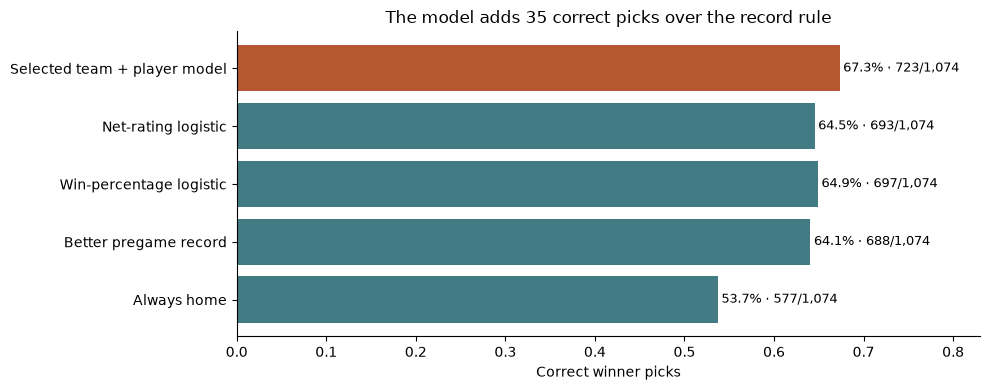

Exact pregame-record ties: 18


In [3]:
decisions = pd.read_csv(TABLES / "decision_baselines.csv")
display(decisions.round(4))
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(
    decisions.strategy,
    decisions.accuracy,
    color=[CLAY if s.startswith("Selected") else TEAL for s in decisions.strategy],
)
for i, row in decisions.iterrows():
    ax.text(
        row.accuracy + 0.004,
        i,
        f"{row.accuracy:.1%} · {row.correct:,}/{row.games:,}",
        va="center",
        fontsize=9,
    )
ax.set(
    xlabel="Correct winner picks",
    xlim=(0, 0.83),
    title="The model adds 35 correct picks over the record rule",
)
finish(fig, "story_record_baseline.png")
print("Exact pregame-record ties:", story["ties"])

The record rule picks **688/1,074 correctly (64.1%)**. The model picks **723/1,074 (67.3%)**, a gain of **35 games or 3.26 percentage points**. This is a more useful benchmark than only reporting that accuracy exceeds 50%. It also shows the model is a modest improvement on a strong rule, not a dramatic reinvention of game prediction.

There are 18 exact winning-percentage ties; home wins the tie-break by definition. Unequal numbers of games do not distort the comparison because it uses percentage, not raw wins.

## 2. Where do the two methods disagree?

An aggregate gain does not say whether the model helps on the difficult games. I count their joint successes and failures. When two binary winner rules disagree, exactly one can be correct.

,Record rule wrong,Record rule right
Model wrong,287,64
Model right,99,624


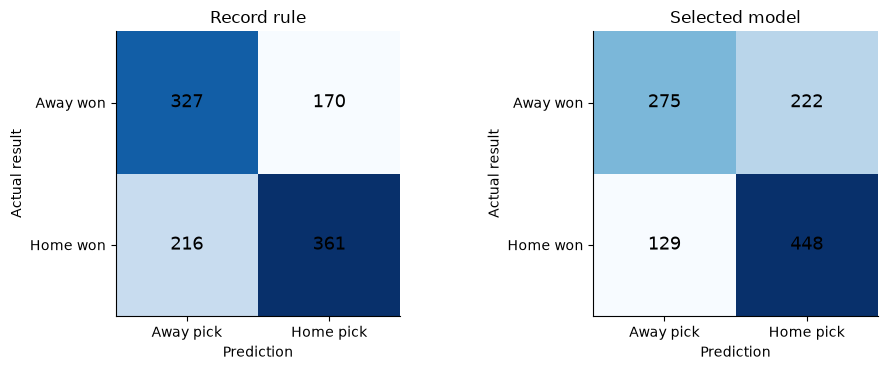

Disagreements: 163; model right: 99; record rule right: 64


In [4]:
joint = pd.crosstab(test.model_correct, test.record_correct).reindex(
    index=[False, True], columns=[False, True], fill_value=0
)
joint.index = ["Model wrong", "Model right"]
joint.columns = ["Record rule wrong", "Record rule right"]
display(joint)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, pick, title in zip(
    axes,
    [test.record_pick_home, test.probability.ge(0.5)],
    ["Record rule", "Selected model"],
):
    matrix = confusion_matrix(test.y, pick, labels=[0, 1])
    ax.imshow(matrix, cmap="Blues")
    for (i, j), value in np.ndenumerate(matrix):
        ax.text(j, i, str(value), ha="center", va="center", fontsize=13)
    ax.set_xticks([0, 1], ["Away pick", "Home pick"])
    ax.set_yticks([0, 1], ["Away won", "Home won"])
    ax.set(title=title, xlabel="Prediction", ylabel="Actual result")
finish(fig, "story_winner_confusion.png")
disagreements = test[~test.agree]
print(
    f"Disagreements: {len(disagreements)}; model right: {disagreements.model_correct.sum()}; record rule right: {disagreements.record_correct.sum()}"
)

The methods disagree on 163 games. The model is correct on 99 and the rule on 64. The difference is exactly the 35 additional correct picks. Home advantage, net rating, schedule and player histories can move the model away from the record's choice; this comparison alone does not identify which feature caused the improvement.

## 3. How uncertain is the accuracy gain?

Games close together can share team form, injuries and schedule conditions, so treating all 1,074 outcomes as independent would be optimistic. I resample complete calendar-week blocks, keeping each game's model and baseline decisions together. Each draw recomputes a game-weighted difference.

,metric,estimate,lower,upper,blocks,repetitions
0,model_accuracy,0.67318,0.63817,0.70983,22,2000
1,record_accuracy,0.64060,0.60351,0.67480,22,2000
2,accuracy_difference,0.03259,0.01380,0.05311,22,2000


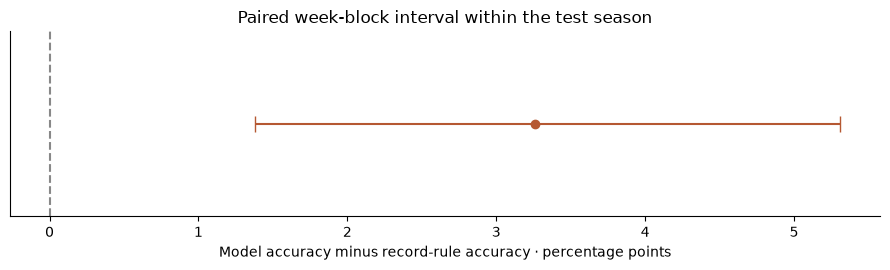

In [5]:
accuracy_interval = paired_accuracy_bootstrap(test, repetitions=2000)
display(accuracy_interval.round(5))
delta = accuracy_interval.set_index("metric").loc["accuracy_difference"]
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.errorbar(
    [100 * delta.estimate],
    [0],
    xerr=[
        [100 * (delta.estimate - delta.lower)],
        [100 * (delta.upper - delta.estimate)],
    ],
    fmt="o",
    capsize=6,
    color=CLAY,
)
ax.axvline(0, color="#888", linestyle="--")
ax.set(
    xlabel="Model accuracy minus record-rule accuracy · percentage points",
    yticks=[],
    title="Paired week-block interval within the test season",
)
finish(fig, "story_accuracy_interval.png")

The 95% interval is approximately **+1.38 to +5.31 percentage points**. It supports a gain within this season for these frozen predictions and this fixed rule. It does not account for model selection, changes between seasons or dependencies crossing week boundaries. Because the rule was added retrospectively, I do not present the comparison as a newly preregistered experiment.

### Does the interval depend on the chosen block length?

One week is an assumption about which nearby games should stay together. I repeat the calculation with nonoverlapping blocks of one, two and four calendar weeks, anchored at the first observed Monday–Sunday week. I report all three choices rather than choose the one giving the strongest result. The last block may be shorter.

Longer blocks preserve more nearby games together, but reduce the number of blocks available to resample. That tradeoff matters in one season. I check both the accuracy difference against the hard record rule and the log-loss difference against the fitted net-rating baseline.

,block_weeks,metric,estimate,lower,upper,blocks,repetitions
0,1,accuracy_difference,0.032588,0.013798,0.053115,22,2000
1,1,delta_log_loss,-0.009528,-0.015518,-0.003192,22,2000
2,2,accuracy_difference,0.032588,0.011842,0.051332,11,2000
3,2,delta_log_loss,-0.009528,-0.015701,-0.002867,11,2000
4,4,accuracy_difference,0.032588,0.011168,0.053140,6,2000
5,4,delta_log_loss,-0.009528,-0.017368,-0.002591,6,2000


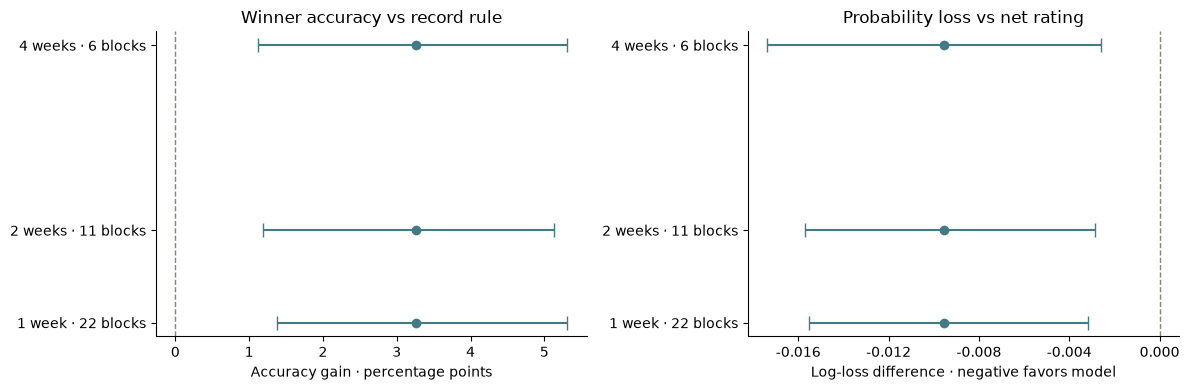

In [6]:
from src.validation import uncertainty_sensitivity
from matplotlib.ticker import MaxNLocator, FormatStrFormatter

sensitivity = uncertainty_sensitivity(test, block_lengths=(1, 2, 4), repetitions=2000)
display(sensitivity.round(6))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, multiplier, title, xlabel in [
    (
        axes[0],
        "accuracy_difference",
        100,
        "Winner accuracy vs record rule",
        "Accuracy gain · percentage points",
    ),
    (
        axes[1],
        "delta_log_loss",
        1,
        "Probability loss vs net rating",
        "Log-loss difference · negative favors model",
    ),
]:
    rows = sensitivity[sensitivity.metric.eq(metric)]
    ax.errorbar(
        multiplier * rows.estimate,
        rows.block_weeks,
        xerr=np.vstack(
            [
                multiplier * (rows.estimate - rows.lower),
                multiplier * (rows.upper - rows.estimate),
            ]
        ),
        fmt="o",
        color=TEAL,
        capsize=5,
    )
    ax.axvline(0, color="#8c8174", linestyle="--", linewidth=1)
    ax.set(
        yticks=[1, 2, 4],
        yticklabels=["1 week · 22 blocks", "2 weeks · 11 blocks", "4 weeks · 6 blocks"],
        title=title,
        xlabel=xlabel,
    )
axes[1].xaxis.set_major_locator(MaxNLocator(5))
axes[1].xaxis.set_major_formatter(FormatStrFormatter("%.3f"))
finish(fig, "story_block_sensitivity.png")

The accuracy-gain intervals remain above zero: **+1.38 to +5.31**, **+1.18 to +5.13**, and **+1.12 to +5.31 percentage points**, respectively. The log-loss intervals also favor the model under all three choices.

That is reassuring about this particular assumption, but four-week resampling has only **six blocks**. These checks neither establish an optimal dependence model nor estimate between-season uncertainty. They do not justify changing the original interval, retuning the model, or calling the retrospective record comparison a newly untouched test.

## 4. Can the model express uncertainty better too?

Winner accuracy discards the difference between a 51% and 90% favorite. The product is a probability, so I retain the original probability comparisons: a historical home rate and fitted logistic models based on record or net rating. The hard record rule has no log loss, Brier score or probability-calibration curve.

In [7]:
scores = pd.read_csv(TABLES / "test_metrics.csv")
display(scores.round(5))
display(pd.read_csv(TABLES / "test_bootstrap.csv").round(5))
example_probabilities = pd.Series([0.51, 0.70, 0.90], name="Home-win probability")
display(
    pd.DataFrame(
        {
            "probability": example_probabilities,
            "log_loss_if_home_loses": -np.log(1 - example_probabilities),
            "brier_if_home_loses": example_probabilities**2,
        }
    ).round(3)
)

,model,selected,log_loss,brier,auc,accuracy,n
0,L1 team_players C=0.1,True,0.60246,0.20797,0.73448,0.67318,1074
1,Home win rate,False,0.69293,0.24988,0.50000,0.53724,1074
2,Baseline win_pct,False,0.61224,0.21289,0.72080,0.64898,1074
3,Baseline net_rating,False,0.61199,0.21271,0.72062,0.64525,1074


,metric,estimate,lower,upper,blocks,repetitions
0,log_loss,0.60246,0.57511,0.62836,22,2000
1,delta_log_loss,-0.00953,-0.01552,-0.00319,22,2000
2,brier,0.20797,0.19598,0.21939,22,2000
3,delta_brier,-0.00474,-0.00742,-0.00202,22,2000


,probability,log_loss_if_home_loses,brier_if_home_loses
0,0.51,0.713,0.26
1,0.70,1.204,0.49
2,0.90,2.303,0.81


The model's log loss is **0.60246**, versus **0.61199** for net rating; Brier score is **0.20797**, versus **0.21271**. The paired week-block loss-difference interval is **−0.01552 to −0.00319**, favoring the model. The small example makes the tradeoff concrete: a 90% favorite that loses is a much worse probability mistake than a 51% favorite that loses, even though both are one incorrect winner pick.

## 5. Did stated probabilities match observed win rates?

Calibration asks whether groups of similar predictions win at roughly the stated rate. I show bin counts and the distribution of predictions so the extremes cannot look more certain than their sample size warrants.

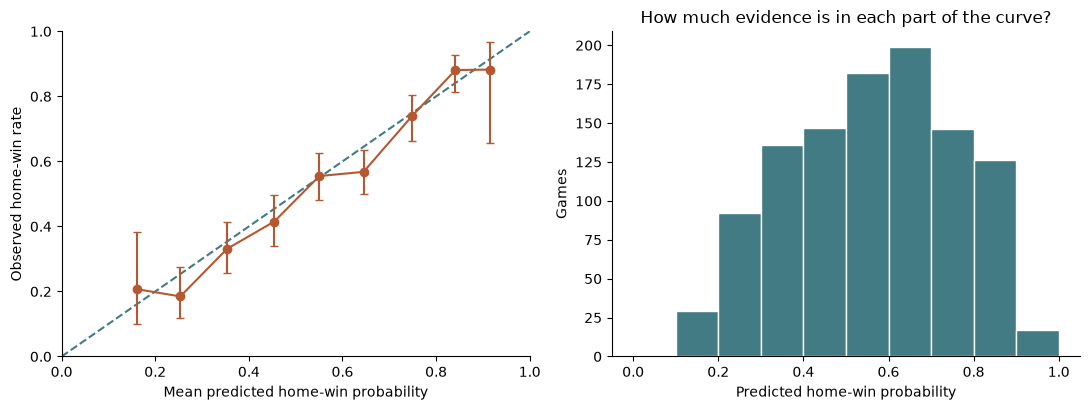

,bin,mean_probability,win_rate,n,lower,upper
0,"(0.1, 0.2]",0.162,0.207,29,0.098,0.384
1,"(0.2, 0.3]",0.254,0.185,92,0.119,0.276
2,"(0.3, 0.4]",0.353,0.331,136,0.257,0.414
3,"(0.4, 0.5]",0.454,0.415,147,0.338,0.496
4,"(0.5, 0.6]",0.551,0.555,182,0.482,0.625
5,"(0.6, 0.7]",0.645,0.568,199,0.498,0.635
6,"(0.7, 0.8]",0.749,0.740,146,0.663,0.804
7,"(0.8, 0.9]",0.841,0.881,126,0.813,0.927
8,"(0.9, 1.0]",0.914,0.882,17,0.657,0.967


{'predicted_home_win_rate': 0.5608, 'observed_home_win_rate': 0.5372, 'calibration_slope': 1.0583, 'calibration_intercept': -0.1259, 'calibration_ece': 0.0367}


In [8]:
cal = pd.read_csv(TABLES / "test_calibration.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot([0, 1], [0, 1], "--", color=TEAL, label="Perfect calibration")
axes[0].errorbar(
    cal.mean_probability,
    cal.win_rate,
    yerr=[cal.win_rate - cal.lower, cal.upper - cal.win_rate],
    fmt="o-",
    capsize=3,
    color=CLAY,
)
axes[0].set(
    xlabel="Mean predicted home-win probability",
    ylabel="Observed home-win rate",
    xlim=(0, 1),
    ylim=(0, 1),
)
axes[1].hist(
    test.probability, bins=np.linspace(0, 1, 11), color=TEAL, edgecolor="white"
)
axes[1].set(
    xlabel="Predicted home-win probability",
    ylabel="Games",
    title="How much evidence is in each part of the curve?",
)
finish(fig, "story_calibration.png")
display(cal[["bin", "mean_probability", "win_rate", "n", "lower", "upper"]].round(3))
print(
    {
        k: round(results[k], 4)
        for k in [
            "predicted_home_win_rate",
            "observed_home_win_rate",
            "calibration_slope",
            "calibration_intercept",
            "calibration_ece",
        ]
    }
)

The model predicts 56.1% home wins on average, while 53.7% occur. The diagnostic calibration slope is 1.058 and intercept −0.126: the slope is near one, but there is an overall offset. Ten-bin absolute calibration error is 0.0367. The 90–100% bin has only 17 games.

Wilson bars describe within-bin uncertainty under an independence assumption; they do not solve schedule dependence. I use these results to understand the model, not to fit a test-season calibration correction. A correction would need a separate chronological calibration design and new evaluation data.

## 6. Separate ranking from calibration

ROC AUC asks whether the model ranks home wins above home losses. It does not require a .5 threshold and does not establish that a stated 70% is numerically correct. Both ranking and calibration matter for the intended product.

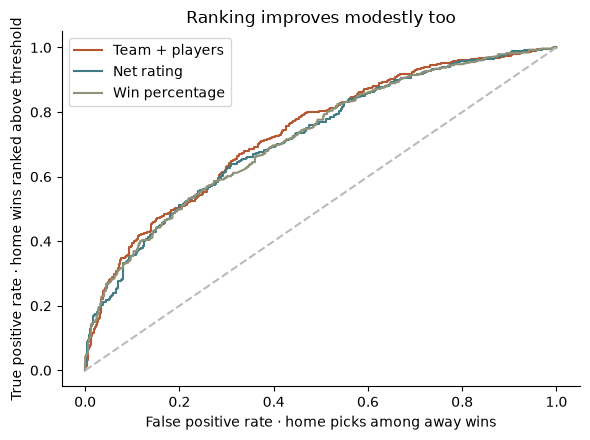

In [9]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for column, label, color in [
    ("probability", "Team + players", CLAY),
    ("net_rating_probability", "Net rating", TEAL),
    ("win_pct_probability", "Win percentage", "#8d9278"),
]:
    fpr, tpr, _ = roc_curve(test.y, test[column])
    ax.plot(fpr, tpr, label=label, color=color)
ax.plot([0, 1], [0, 1], "--", color="#bbb")
ax.set(
    xlabel="False positive rate · home picks among away wins",
    ylabel="True positive rate · home wins ranked above threshold",
    title="Ranking improves modestly too",
)
ax.legend()
finish(fig, "story_roc.png")

AUC rises from about 0.721 for the simple fitted strength baselines to 0.734 for the selected model. The difference is modest, consistent with the winner and probability comparisons. I do not optimize a threshold on this curve: the historical game selector continues to call the side above 50% the favorite.

## 7. What tends to favor one team?

The fitted coefficients describe conditional associations between home-minus-away inputs and home-win log odds. Standardization makes their scales comparable. Strong correlation still means that credit can move between related inputs.

,feature,coefficient,odds_multiplier_per_sd,training_sd
0,net_rating_diff,0.4979,1.6453,7.2027
1,win_pct_diff,0.2151,1.2399,0.2262
2,back_to_back_diff,-0.1139,0.8924,0.5163
3,scoring_concentration_diff,0.0932,1.0976,0.0228
4,weighted_absence_diff,-0.0594,0.9424,0.1108
5,weighted_ppa_diff,0.0557,1.0572,0.1062
6,weighted_participation_diff,0.0512,1.0525,0.0996
7,games_last7_diff,-0.0482,0.9529,0.8369
8,ft_rate_diff,-0.0413,0.9596,0.0392
9,dreb_rate_diff,0.0300,1.0305,0.0253


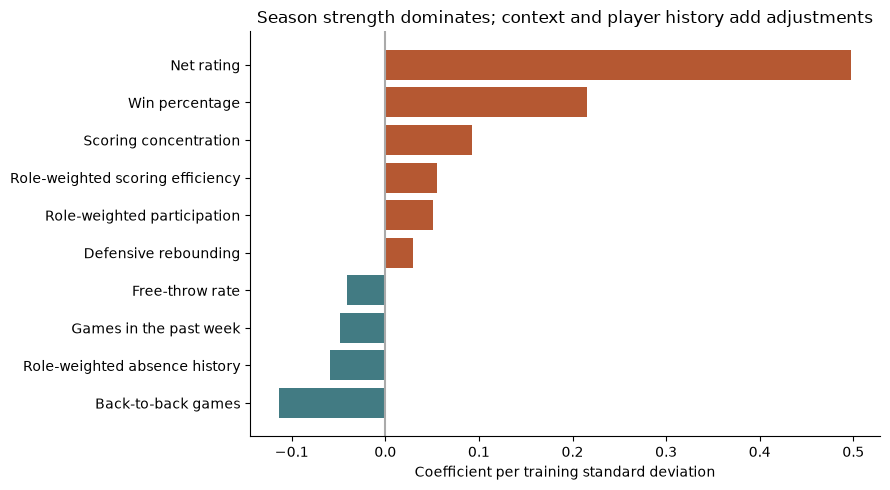

,feature,coefficient
19,top7_share_diff,0.0
20,minute_continuity_diff,0.0
21,top5_share_diff,0.0


Illustration: from an otherwise 50% matchup, +5 net-rating points changes the probability to 0.5855651329604263


In [10]:
importance = pd.read_csv(TABLES / "importance.csv")
display(
    importance[["feature", "coefficient", "odds_multiplier_per_sd", "training_sd"]]
    .head(10)
    .round(4)
)
fig, ax = plt.subplots(figsize=(9, 5))
top = importance.head(10).sort_values("coefficient")
ax.barh(
    top.feature.map(feature_label),
    top.coefficient,
    color=[CLAY if x > 0 else TEAL for x in top.coefficient],
)
ax.axvline(0, color="#aaa")
ax.set(
    xlabel="Coefficient per training standard deviation",
    title="Season strength dominates; context and player history add adjustments",
)
finish(fig, "story_final_coefficients.png")
display(importance[importance.coefficient.eq(0)][["feature", "coefficient"]])
beta = importance.set_index("feature").loc["net_rating_diff", "coefficient_per_unit"]
print(
    "Illustration: from an otherwise 50% matchup, +5 net-rating points changes the probability to",
    1 / (1 + np.exp(-5 * beta)),
)

Nineteen of twenty-two coefficients are nonzero. Minute continuity and top-five/top-seven minute share shrink to zero; they remain useful explorer statistics but are not active predictors in this fit. Net rating's standardized coefficient is about .498, an odds multiplier of 1.65 per training standard deviation. The displayed five-point illustration is a conditional model calculation, not a causal promise or a claim that correlated team statistics would truly stay fixed.

## 8. Trace one actual probability to its inputs

For a concrete forecast, I take the most confident test disagreement where the model beat the record rule. This is a retrospective explanation selected to be inspectable, not a representative example chosen before the result. I also examine the strongest disagreement where the rule won immediately afterward.

In [11]:
wins = test[test.model_correct & ~test.record_correct].sort_values(
    "confidence", ascending=False
)
losses = test[~test.model_correct & test.record_correct].sort_values(
    "confidence", ascending=False
)
case = wins.iloc[0]
display(
    pd.concat([wins.head(1), losses.head(1)])[
        [
            "gamedate",
            "away_off_team",
            "home_off_team",
            "away_prior_wins",
            "away_prior_games",
            "home_prior_wins",
            "home_prior_games",
            "probability",
            "home_points",
            "away_points",
            "model_correct",
            "record_correct",
        ]
    ]
)
bundle = joblib.load(ROOT / "artifacts/models/frozen_models.joblib")[
    selection["config"]["name"]
]
inputs = pd.read_csv(TABLES / "matchups.csv.gz")
one = inputs[inputs.nbagameid.eq(case.nbagameid)]
contributions = linear_contributions(bundle, one)
intercept = float(bundle["model"][-1].intercept_[0])
logit = intercept + contributions.contribution.sum()
probability = 1 / (1 + np.exp(-logit))
print(
    "Intercept:",
    intercept,
    "Sum of contributions:",
    contributions.contribution.sum(),
    "Reconstructed probability:",
    probability,
)
np.testing.assert_allclose(probability, case.probability, atol=1e-9)

,gamedate,away_off_team,home_off_team,away_prior_wins,away_prior_games,home_prior_wins,home_prior_games,probability,home_points,away_points,model_correct,record_correct
982,2024-04-03,CLE,PHX,46,76,44,75,0.691865,122,101,True,False
823,2024-03-13,CLE,NOP,41,65,39,64,0.690726,95,116,False,True


Intercept: 0.3305528442497632 Sum of contributions: 0.478302067328377 Reconstructed probability: 0.6918654392368646


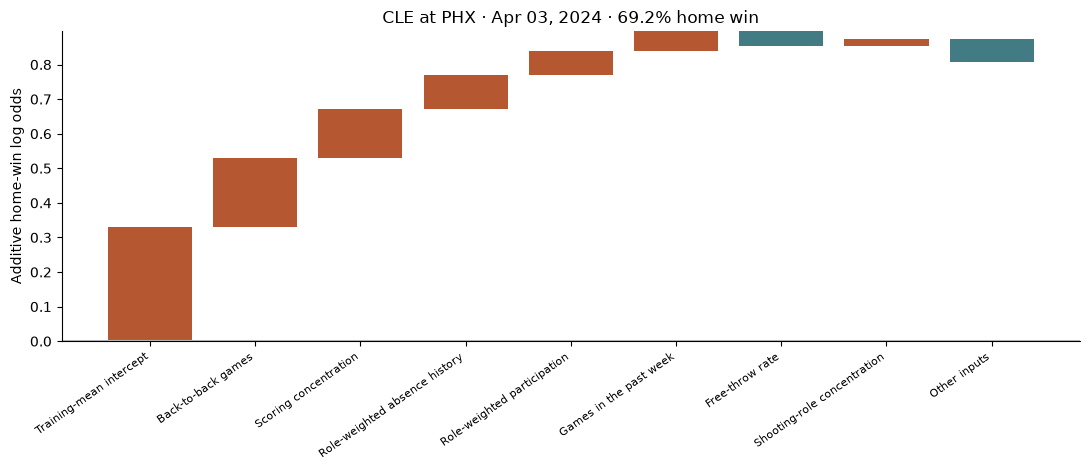

,nbagameid,feature,contribution
9,22301110,back_to_back_diff,0.1985
17,22301110,scoring_concentration_diff,0.1431
20,22301110,weighted_absence_diff,0.0966
21,22301110,weighted_participation_diff,0.0716
10,22301110,games_last7_diff,0.0558
7,22301110,ft_rate_diff,-0.0425
18,22301110,usage_concentration_diff,0.0209
5,22301110,oreb_rate_diff,-0.0180
0,22301110,net_rating_diff,-0.0176
1,22301110,win_pct_diff,-0.0140


In [12]:
ordered = contributions.reindex(
    contributions.contribution.abs().sort_values(ascending=False).index
)
top = ordered.head(7).copy()
other = ordered.iloc[7:].contribution.sum()
labels = [
    "Training-mean intercept",
    *[feature_label(x) for x in top.feature],
    "Other inputs",
]
increments = np.array([intercept, *top.contribution, other])
starts = np.r_[0, np.cumsum(increments)[:-1]]
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.bar(
    range(len(labels)),
    increments,
    bottom=starts,
    color=[CLAY if x >= 0 else TEAL for x in increments],
)
ax.axhline(0, color="#bbb")
ax.set_xticks(range(len(labels)), labels, rotation=35, ha="right", fontsize=8)
ax.set(
    ylabel="Additive home-win log odds",
    title=f"{case.away_off_team} at {case.home_off_team} · {case.gamedate:%b %d, %Y} · {case.probability:.1%} home win",
)
finish(fig, "story_prediction_trace.png")
display(ordered.head(10).round(4))

Phoenix–Cleveland on April 3 illustrates a successful departure from the standings; New Orleans–Cleveland on March 13 illustrates an unsuccessful one. The additive trace reconstructs the stored probability exactly. Its intercept corresponds to training-mean standardized differences, not a literal equal-team matchup. The contributions show how the model computed its forecast; they cannot prove why the game ended as it did.

## 9. Look at the confident mistakes without inventing explanations

It is easy to showcase only favorable disagreements. I also inspect the largest wrong probabilities across the entire test and examine which teams were systematically above or below the model's expectations.

,gamedate,away_off_team,home_off_team,away_points,home_points,probability,confidence,record_correct
1054,2024-04-12,DET,DAL,107,89,0.915,0.915,False
481,2024-01-22,CHA,MIN,128,125,0.912,0.912,False
337,2024-01-02,CHA,SAC,111,104,0.894,0.894,False
525,2024-01-28,OKC,DET,104,120,0.121,0.879,False
89,2023-11-27,POR,IND,114,110,0.869,0.869,False
224,2023-12-18,CHI,PHI,108,104,0.866,0.866,False
37,2023-11-20,BOS,CHA,118,121,0.134,0.866,False
996,2024-04-05,TOR,MIL,117,111,0.859,0.859,False
711,2024-02-27,DET,CHI,105,95,0.845,0.845,False
120,2023-12-01,MEM,DAL,108,94,0.840,0.840,False


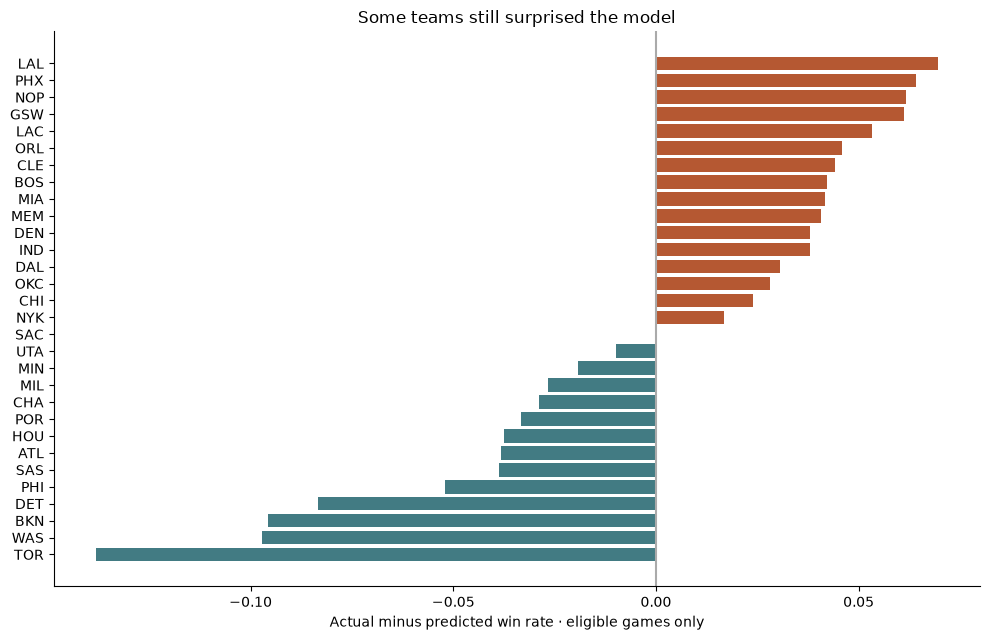

In [13]:
misses = test[~test.model_correct].sort_values("confidence", ascending=False)
display(
    misses[
        [
            "gamedate",
            "away_off_team",
            "home_off_team",
            "away_points",
            "home_points",
            "probability",
            "confidence",
            "record_correct",
        ]
    ]
    .head(10)
    .round({"probability": 3, "confidence": 3})
)
errors = pd.read_csv(TABLES / "team_errors.csv")
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(
    errors.team,
    errors.actual_minus_predicted,
    color=[CLAY if x > 0 else TEAL for x in errors.actual_minus_predicted],
)
ax.axvline(0, color="#aaa")
ax.set(
    xlabel="Actual minus predicted win rate · eligible games only",
    title="Some teams still surprised the model",
)
finish(fig, "story_team_errors.png")

Dallas was a 91.5% favorite against Detroit on April 12 and lost 89–107. Minnesota was a 91.2% favorite against Charlotte on January 22 and lost 125–128. Those are real limitations of the forecast, but the supplied histories do not establish an injury, trade or tactical explanation.

Toronto won 27.8% of eligible games against a 41.6% predicted rate. The Lakers won 59.2% against 52.2% predicted. These are errors on the modeled subset, not reconstructed full-season records, and they are not a reason to tune team-specific corrections on the test.

## 10. Is the headline hiding a particular part of the season?

The warmup already excludes the first ten games per team. I inspect later coverage by the smaller of the teams' prior game counts, and check favorite reliability by confidence band. These are post-evaluation diagnostics with counts, not extra opportunities to pick the best-looking subgroup.

,stage_of_season,games,model_accuracy,record_accuracy
0,10–24 prior games,228,0.7018,0.6886
1,25–49 prior games,372,0.6720,0.6290
2,50+ prior games,474,0.6603,0.6266


,confidence_band,games,predicted_favorite_rate,actual_favorite_rate
0,50–60%,329,0.5485,0.5684
1,60–70%,335,0.6457,0.6090
2,70–80%,238,0.7478,0.7689
3,80–90%,155,0.8408,0.8645
4,90–100%,17,0.9143,0.8824


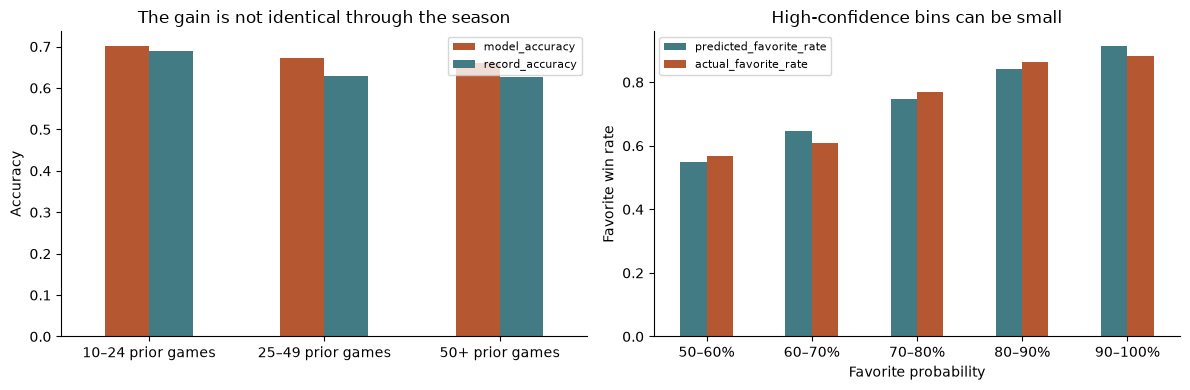

In [14]:
stages = pd.read_csv(TABLES / "test_season_stages.csv")
favorites = pd.read_csv(TABLES / "test_favorites.csv")
display(stages.round(4))
display(favorites.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
stages.set_index("stage_of_season")[["model_accuracy", "record_accuracy"]].plot.bar(
    ax=axes[0], color=[CLAY, TEAL], rot=0
)
axes[0].set(
    xlabel="", ylabel="Accuracy", title="The gain is not identical through the season"
)
favorites.set_index("confidence_band")[
    ["predicted_favorite_rate", "actual_favorite_rate"]
].plot.bar(ax=axes[1], color=[TEAL, CLAY], rot=0)
axes[1].set(
    xlabel="Favorite probability",
    ylabel="Favorite win rate",
    title="High-confidence bins can be small",
)
for ax in axes:
    ax.legend(fontsize=8)
finish(fig, "story_error_slices.png")

The model beats the record rule in all three broad stages here, but the gain is smaller in the 10–24-game group. The strongest favorites win 15 of 17 games; a couple of outcomes materially change that rate. These checks support a measured result rather than a universal claim about every matchup type.

## 11. Where did player histories change the development forecast?

The final test comparison demonstrates the complete model's gain. To understand why player histories were included, I return to the development comparison with the same L1 penalty and team inputs, adding only the player-history set. This keeps the evidence for the design decision separate from the final evaluation.

In [15]:
changes = pd.read_csv(TABLES / "player_prediction_changes.csv")
display(
    changes[
        [
            "gamedate",
            "away_off_team",
            "home_off_team",
            "L1 team C=0.1",
            "L1 team_players C=0.1",
            "probability_change",
            "weighted_absence_diff",
            "y",
        ]
    ]
    .head(8)
    .round(3)
)
display(pd.read_csv(TABLES / "player_comparison_by_season.csv").round(5))

,gamedate,away_off_team,home_off_team,L1 team C=0.1,L1 team_players C=0.1,probability_change,weighted_absence_diff,y
0,2023-04-09,HOU,WAS,0.737,0.575,-0.162,0.335,0
1,2023-04-07,HOU,CHA,0.642,0.489,-0.153,0.362,0
2,2022-02-08,BOS,BKN,0.523,0.374,-0.149,0.273,0
3,2022-01-07,ATL,LAL,0.566,0.711,0.145,-0.263,1
4,2020-01-05,MIN,CLE,0.454,0.589,0.136,-0.236,0
5,2021-05-14,NOP,GSW,0.648,0.783,0.135,-0.065,1
6,2022-01-09,MEM,LAL,0.554,0.687,0.133,-0.175,0
7,2022-12-30,PHI,NOP,0.621,0.491,-0.131,0.148,1


,season,Baseline net_rating,L1 team C=0.1,L1 team_players C=0.1,players_minus_team
0,2017,0.61454,0.61134,0.60649,-0.00485
1,2018,0.62147,0.61796,0.61433,-0.00363
2,2019,0.62458,0.62113,0.62089,-0.00024
3,2020,0.63266,0.63019,0.62441,-0.00578
4,2021,0.64194,0.64241,0.63714,-0.00527
5,2022,0.64832,0.64572,0.64662,0.00090


Player histories improve five of six development seasons, with some substantial forecast changes in individual games. Because the two models are separately fitted and their inputs are correlated, the difference is not a causal effect of a particular player's absence. It is evidence about a modeling choice under the supplied information constraints.

## What I would carry forward

The project now has a concrete answer to its basketball question: historical team and player data can produce useful pregame probabilities, and this frozen model improves over a simple better-record rule in the evaluated season. The gain is **35 additional correct picks**, accompanied by better log loss and Brier score than the fitted strength baselines.

The main limitations are equally concrete: opening-game coverage, stale roster membership, no current availability timestamps, neutral sites, correlated predictors, repeated model search and only one independent test season. A future revision should evaluate a genuinely new season before making stronger claims. Season-start priors or timestamped roster information would be candidates for that future development work, not additions justified by this test's misses.

The Streamlit app follows the same route: basketball questions → feature construction → model comparison → final performance → individual games and errors. It makes the evidence inspectable without requiring every visitor to read the modeling code.